# 6. Your first OD solution

> Estimate the OSIRIS-REx trajectory from the week of simulated tracking with a batch square-root information filter, then inspect the solution: convergence, residuals, uncertainty, and errors against the truth.
>
> ⏱ ~15 min &nbsp;·&nbsp; **Prereqs:** [4. The filter's dynamics model](04_filter_dynamics.ipynb), [5. The filter's measurement model](05_filter_measurements.ipynb) &nbsp;·&nbsp; **Uses:** `outputs/02_truth_dynamics/truth.bsp`, `outputs/03_tracking_data/*.json` &nbsp;·&nbsp; **Produces:** `outputs/06_first_od_solution/solution.json` &nbsp;·&nbsp; **Next:** [7. Sequential filtering & process noise](07_sequential_filtering.ipynb)

Chapters 4 and 5 built the two halves of the problem: a reference trajectory with its STM and a-priori covariance, and the measurement models with their residuals and partials. A batch filter combines them: it maps every observation to the epoch $t_0$ through $\tilde H_k \Phi(t_k, t_0)$, solves the weighted least-squares problem for $\delta x_0$, and iterates until the reference stops changing.

## Setup

The filter's dynamics model (chapter 4) and measurement model (chapter 5). The truth is loaded only to evaluate the solution.

**Starting here?** This chapter reads the outputs of chapters 2 and 3. Run `python prepare.py 06` from `tutorials/v2/` to generate them (about 15 s); the setup cell stops with a message if they are missing.

In [ ]:
import contextlib
import io
import json
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import scarabaeus as scb

out = Path("outputs/06_first_od_solution")
shutil.rmtree(out, ignore_errors=True)
out.mkdir(parents=True)
tracking_dir = Path("outputs/03_tracking_data")  # produced by chapter 3

# Inputs from earlier chapters. Starting here? Run `python prepare.py 06` first.
if not (
    Path("outputs/02_truth_dynamics/truth.bsp").exists()
    and len(list(tracking_dir.glob("*.json"))) == 6
):
    raise FileNotFoundError(
        "This chapter reads the truth trajectory (chapter 2) and the tracking data (chapter 3). "
        "Run those chapters, or `python prepare.py 06` from tutorials/v2/ (about 15 s)."
    )

scb.SpiceManager.clear_kernels()
scb.SpiceManager.load_kernel_from_mkfile("orex_approach.tm")
scb.SpiceManager.load_kernel(
    "outputs/02_truth_dynamics/truth.bsp"
)  # produced by chapter 2

kg, km, m, mm, sec, minute, day = scb.Units.get_units(
    ["kg", "km", "m", "mm", "sec", "min", "day"]
)
J2000 = scb.Frame("J2000")
sun = scb.CelestialBody.from_constants("SUN")
epochs = scb.EpochArray.interval(
    scb.SpiceManager.utc2et("2018-06-01T00:00:00"),
    scb.SpiceManager.utc2et("2018-06-08T00:00:00"),
    dt=scb.ArrayWUnits(30, minute),
    sys="TDB",
)

# --- the filter's dynamics model (chapter 4) ---
orex = scb.Spacecraft("OREx truth", -64000)
reference = scb.Spacecraft(
    "OREx reference",
    -64001,
    scb.ArrayWUnits(1500.0, kg),
    scb.ArrayWUnits(11.0, m**2).convert_to(km**2),
    scb.ArrayWUnits(1.2, None),
)
planets = ["MERCURY", "VENUS", "EARTH", "MARS", "JUPITER", "SATURN"]

x_truth0 = orex.get_state(epochs[0], reference_frame="J2000", origin="SUN")
r_apriori = x_truth0.quantity[:3] + scb.ArrayWUnits([10.0] * 3, km)
v_apriori = x_truth0.quantity[3:] + scb.ArrayWUnits([0.01] * 3, m / sec).convert_to(
    km / sec
)
state = (
    scb.StateDefinition()
    .position(reference, scb.ArrayWFrame(r_apriori, J2000))
    .velocity(reference, scb.ArrayWFrame(v_apriori, J2000))
)

propagator = scb.Propagator(
    primary_body=reference,
    state_vector=scb.StateArray(epoch=epochs[0], origin=sun, state=state),
    tspan=epochs,
    force_models=scb.ForceModelTranslation(
        reference, third_bodies=planets, cannonball_SRP=True
    ),
)
P0 = scb.CovarianceMatrix(
    [scb.ArrayWUnits(100.0, km)] * 3
    + [scb.ArrayWUnits(0.1, m / sec).convert_to(km / sec)] * 3,
    epochs[0],
    from_list=True,
)

# --- the filter's measurement model (chapter 5) ---
stations = {dss: scb.GroundStation(dss) for dss in ["DSS-14", "DSS-43", "DSS-63"]}
models = []
for dss, station in stations.items():
    models.append(
        scb.RangeIdeal(
            f"{dss} range", station, sigma=scb.ArrayWUnits(2.0, m).convert_to(km)
        )
    )
    models.append(
        scb.RangeRateIdeal(
            f"{dss} range-rate",
            station,
            sigma=scb.ArrayWUnits(0.1, mm / sec).convert_to(km / sec),
        )
    )

tracking = scb.MeasurementSpec.many(
    *[
        scb.MeasurementSpec(
            model=model,
            dataset_name=model.name,
            observed_meas=model.observed_measurements(
                str(tracking_dir / f"{model.name.replace(' ', '_')}.json"),
                units=model.sigma.units,
            ),
        )
        for model in models
    ]
)

## 1. Filter settings

`FilterSettings` collects everything about the estimation problem that is not the dynamics or the data:

<div style="border-left:4px solid #2563eb; background:rgba(37,99,235,0.12); padding:6px 10px; border-radius:4px">
🔵 <b>TODO:</b> 
</div>

| Setting | Purpose | Chapter |
|---|---|---|
| `initial_covariance` | a-priori covariance $P_0$ | 4 |
| `initial_deviation` | a-priori deviation $\bar x_0$ (default zero) | 4 |
| `process_noise` | stochastic acceleration model (`ProcessNoiseSettings`) | 7 |
| `measurement_sigmas` | per-dataset σ overrides | ? |
| `covariance_analysis` | covariance-only run, no state update | 8 |
| `editing_method`, `editing_datasets`, `editing_kwargs` | measurement editing (outlier rejection) | 8 |
| `output` | what the solution stores (`OutputSettings`) | |

`OutputSettings` controls the stored quantities. Residuals, the covariance history and the state deviation history are kept by default; debugging quantities (Kalman gains, innovation covariances, NIS) are off. Free-form `metadata` travels with the solution.

In [ ]:
settings = scb.FilterSettings(
    initial_covariance=P0,
    output=scb.OutputSettings(
        metadata={"scenario": "OSIRIS-REx approach, 2018-06-01 to 06-08", "chapter": 6}
    ),
)

## 2. The batch filter

Scarabaeus has two batch filters with the same interface:

- `LSB`: least-squares batch, solving the normal equations $\left(P_0^{-1} + \sum_k H_k^T R_k^{-1} H_k\right)\delta x_0 = \sum_k H_k^T R_k^{-1} y_k$, with $H_k = \tilde H_k \Phi(t_k, t_0)$;
- `SRIFB`: batch square-root information filter, which solves the same problem with orthogonal (Householder) transformations on the square root of the information matrix, avoiding the loss of precision of forming $H^T R^{-1} H$ explicitly.

We use `SRIFB`. The constructor takes the reference propagator (chapter 4), the `MeasurementSpec` (chapter 5) and the settings, propagates the reference, and evaluates the measurements on it. The reference is written to SPK as `reference.bsp`, with one file per iteration.

## 3. Iterating to convergence

`fit()` solves for $\delta x_0$, re-propagates the reference from $x^*_0 + \delta x_0$, re-evaluates the residuals and partials, and repeats until the RMS of the correction falls below `convergence_threshold` or `max_iterations` is reached. It returns the solution, the number of iterations, and whether it converged.

<div style="border-left:4px solid #2563eb; background:rgba(37,99,235,0.12); padding:6px 10px; border-radius:4px">
🔵 <b>TODO:</b> verbosity for filter as well
</div>

In [ ]:
# TODO: the filter prints ~350 kB of progress output; redirect it until Scarabaeus has a verbosity switch
filter_log = io.StringIO()
with contextlib.redirect_stdout(filter_log), contextlib.redirect_stderr(filter_log):
    srifb = scb.SRIFB(
        propagator=propagator,
        measurements=tracking,
        settings=settings,
        traj_name="reference.bsp",
        traj_dir=str(out),
    )
    solution, n_iterations, converged = srifb.fit(
        traj_name="reference.bsp",
        traj_dir=str(out),
        max_iterations=10,
        convergence_threshold=1e-5,
    )

print(f"Converged: {converged} after {n_iterations} iterations")

Converged: True after 3 iterations


The convergence test is the RMS of the six components of $\delta x_0$ in km and km/s, so the threshold of $10^{-5}$ corresponds to a position correction of about 1 cm.

## 4. Solution statistics

`print_stats` summarizes the solution: the post-fit χ² test and the formal 1σ uncertainties at the first and last measurement epochs.

In [4]:
solution.print_stats()

ORBIT DETERMINATION SOLUTION STATISTICS

Solution Overview:
  Number of epochs:        270
  Number of states:        6
  Covariance analysis:     False

Chi-Squared Test:
  Chi-squared value:       600.0717
  Degrees of freedom:      626
  Normalized chi-squared:  0.9586
  Status:                  Filter appears well-tuned

Covariance Information:
  Initial position uncertainty (1σ):
    X: 7.540777e-01 km
    Y: 9.212231e-01 km
    Z: 1.017740e+00 km
    RSS: 1.566231e+00 km
  Final position uncertainty (1σ):
    X: 8.402855e-01 km
    Y: 9.462019e-01 km
    Z: 1.125326e+00 km
    RSS: 1.693439e+00 km
  Initial velocity uncertainty (1σ):
    VX: 3.017435e-07 km/s
    VY: 1.175928e-06 km/s
    VZ: 9.514246e-07 km/s
    RSS: 1.542422e-06 km/s
  Final velocity uncertainty (1σ):
    VX: 2.921283e-07 km/s
    VY: 1.175687e-06 km/s
    VZ: 9.518281e-07 km/s
    RSS: 1.540635e-06 km/s


A normalized χ² close to 1 means the post-fit residuals are consistent with the measurement σ, as expected when the filter's models match those that generated the data.

## 5. Saving the solution

`save` writes the solution, including every iteration, to a single JSON file:

In [5]:
with contextlib.redirect_stdout(filter_log):
    solution.save(out / "solution.json")

with open(out / "solution.json") as f:
    record = json.load(f)

print("top-level keys:", list(record))
print("metadata:      ", record["metadata"])
print("per iteration: ", list(record["final"]))

top-level keys: ['metadata', 'iter_1', 'iter_2', 'iter_3', 'final']
metadata:       {'n_states': 6, 'is_covariance_analysis': False, 'n_iterations': 3, 'scenario': 'OSIRIS-REx approach, 2018-06-01 to 06-08', 'chapter': 6}
per iteration:  ['timestamps', 'deviation_estimated', 'deviation_cumulative', 'state_estimated', 'covariance_diagonals', 'prefits', 'postfits']


The file is self-contained, so the iteration history can be read back from it. For each iteration: the size of the correction (at the first measurement epoch) and the RMS of the normalized pre-fit residuals of that iteration's reference:

In [ ]:
print(
    f"{'iteration':>9s} {'|δr| [km]':>12s} {'|δv| [mm/s]':>12s} {'pre-fit RMS/σ':>14s}"
)
for k in range(1, record["metadata"]["n_iterations"] + 1):
    iteration = record[f"iter_{k}"]
    dx = iteration["deviation_estimated"][0]
    z = [r / s for dataset in iteration["prefits"].values() for r, s in dataset]
    print(
        f"{k:9d} {sum(c**2 for c in dx[:3])**0.5:12.3e} {sum(c**2 for c in dx[3:])**0.5 * 1e6:12.3e}"
        f" {(sum(v**2 for v in z) / len(z))**0.5:14.2f}"
    )

iteration    |δr| [km]  |δv| [mm/s]  pre-fit RMS/σ
        1    1.741e+01    1.754e+01        7890.57
        2    1.294e-04    5.652e-04           0.97
        3    7.721e-06    1.182e-05           0.97


The first iteration removes almost all of the 17 km / 1.7 cm/s a-priori error: as chapter 4 showed, the problem is nearly linear at this scale. The second iteration corrects the remaining linearization error of about 10 cm, and the third (under 1 cm) confirms convergence. The pre-fit residuals fall from thousands of σ to the noise level.

## 6. Residuals

The same history shows the residuals before and after the fit: pre-fit residuals on the a-priori reference (iteration 1) and post-fit residuals of the converged solution, normalized by σ:

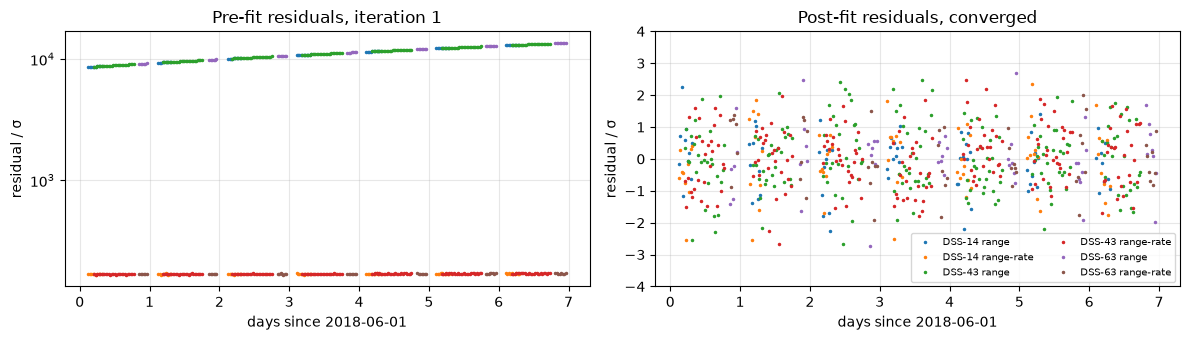

In [ ]:
observation_epochs = {
    spec["dataset_name"]: spec["observed_meas"][0] for spec in tracking
}

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
for model in models:
    t_meas = (observation_epochs[model.name] - epochs[0]).convert_to(day).values
    first = [r / s for r, s in record["iter_1"]["prefits"][model.name]]
    final = [r / s for r, s in solution.postfits[model.name]]
    ax[0].plot(t_meas, first, ".", ms=3, label=model.name)
    ax[1].plot(t_meas, final, ".", ms=3, label=model.name)
ax[0].set(
    xlabel="days since 2018-06-01",
    ylabel="residual / σ",
    title="Pre-fit residuals, iteration 1",
    yscale="symlog",
)
ax[1].set(
    xlabel="days since 2018-06-01",
    ylabel="residual / σ",
    title="Post-fit residuals, converged",
    ylim=(-4, 4),
)
ax[1].legend(fontsize=7, ncol=2, loc="lower right")
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()

## 7. The estimate

At convergence the reference trajectory *is* the estimate: the last correction is negligible, and the final reference SPK (loaded by the filter) gives the estimated state at any epoch in the arc. `propagate_covariance` maps the solution covariance to any epoch. At $t_0$:

In [ ]:
x_est0 = reference.get_state(epochs[0], reference_frame="J2000", origin="SUN").quantity
P_est0 = solution.propagate_covariance(epochs[0:1])[0]

error_apriori = (r_apriori - x_truth0.quantity[:3]).values.tolist() + (
    v_apriori - x_truth0.quantity[3:]
).values.tolist()
error_estimate = (x_est0 - x_truth0.quantity).values
sigma_estimate = P_est0.diagonal() ** 0.5

labels = ["x [km]", "y [km]", "z [km]", "vx [mm/s]", "vy [mm/s]", "vz [mm/s]"]
scale = [1, 1, 1, 1e6, 1e6, 1e6]
print(
    f"{'':10s} {'a-priori error':>15s} {'estimate error':>15s} {'1-sigma':>8s} {'error/sigma':>8s}"
)
for i, label in enumerate(labels):
    print(
        f"{label:10s} {error_apriori[i] * scale[i]:15.3f} {error_estimate[i] * scale[i]:15.3f}"
        f" {sigma_estimate[i] * scale[i]:8.3f} {error_estimate[i] / sigma_estimate[i]:+8.2f}"
    )

            a-priori error  estimate error       1σ  error/σ
x [km]              10.000          -0.430    0.753    -0.57
y [km]              10.000           0.470    0.926    +0.51
z [km]              10.000           0.157    1.018    +0.15
vx [mm/s]           10.000          -0.084    0.302    -0.28
vy [mm/s]           10.000          -1.164    1.176    -0.99
vz [mm/s]           10.000           0.984    0.951    +1.03


The estimation error is within about 1σ in every component: the formal covariance is a realistic description of the actual error.

## 8. Errors over the arc

The solution also stores the estimated state (`state_est`) and covariance (`covariance_est`) at every measurement epoch, which can be compared with the truth along the whole arc:

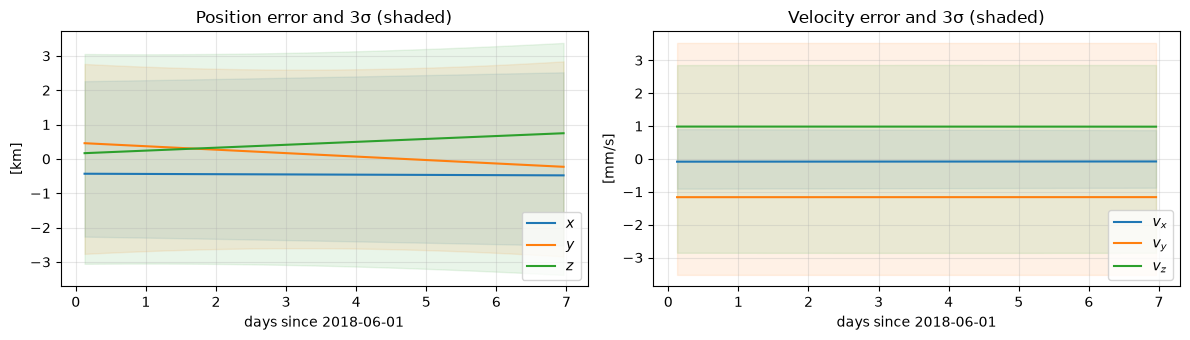

In [ ]:
t_est = scb.EpochArray(solution.timestamps, sys="TDB")
t_days = (t_est - epochs[0]).convert_to(day).values

# TODO(draft): get_state takes one epoch at a time; replace the loop once it accepts an EpochArray
x_true = [
    orex.get_state(t, reference_frame="J2000", origin="SUN").quantity.values
    for t in t_est
]
error = solution.state_est - x_true
sigma3 = [3 * P.diagonal() ** 0.5 for P in solution.covariance_est]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for i, c in enumerate("xyz"):
    (line,) = ax[0].plot(t_days, error[:, i], label=f"${c}$")
    ax[0].fill_between(
        t_days,
        [-s[i] for s in sigma3],
        [s[i] for s in sigma3],
        color=line.get_color(),
        alpha=0.1,
    )
    (line,) = ax[1].plot(t_days, error[:, 3 + i] * 1e6, label=f"$v_{c}$")
    ax[1].fill_between(
        t_days,
        [-s[3 + i] * 1e6 for s in sigma3],
        [s[3 + i] * 1e6 for s in sigma3],
        color=line.get_color(),
        alpha=0.1,
    )
ax[0].set(
    xlabel="days since 2018-06-01",
    ylabel="[km]",
    title="Position error and 3-sigma (shaded)",
)
ax[1].set(
    xlabel="days since 2018-06-01",
    ylabel="[mm/s]",
    title="Velocity error and 3-sigma (shaded)",
)
for a in ax:
    a.legend()
    a.grid(alpha=0.3)
plt.tight_layout()

Over one week of a heliocentric orbit, gravity barely changes an error: the velocity error stays nearly constant and the position error grows linearly at that rate (e.g. $v_y \approx -1.2$ mm/s gives the −0.7 km drift in $y$). Without process noise, the whole curve is one initial-state error carried forward by the dynamics; its sign and size come from this noise realization, not a bias.

## 9. The shape of the uncertainty

A position uncertainty of about 1 km per axis may seem large for 2 m range data. The covariance is far from isotropic: two-way range measures the distance along the line of sight directly, while the plane-of-sky position is inferred only indirectly, through the dynamics and the diurnal range-rate signature (chapter 3). Projecting the covariance at the end of the arc onto the Earth–spacecraft line of sight:

In [ ]:
t_end = epochs[-1]
line_of_sight = reference.get_state(
    t_end, reference_frame="J2000", origin="EARTH"
).quantity[:3]
u = (line_of_sight / line_of_sight.norm()).values
P_pos = solution.propagate_covariance(epochs[-1:])[0][:3, :3]

sigma_los = (u @ P_pos @ u) ** 0.5
sigma_total = P_pos.trace() ** 0.5
print(f"1-sigma along the line of sight: {sigma_los * 1e3:.2f} m")
print(
    f"1-sigma in the plane of sky:     {(sigma_total**2 - sigma_los**2) ** 0.5:.2f} km (RSS of the two transverse directions)"
)

1σ along the line of sight: 0.45 m
1σ in the plane of sky:     1.69 km (RSS of the two transverse directions)


The position is known to well under a meter along the line of sight and to about a kilometer across it. This geometry is typical of Earth-based radiometric tracking of a distant spacecraft, and it is the motivation for adding data types that measure the plane of sky directly, such as ΔDOR or optical navigation <div style="border-left:4px solid #2563eb; background:rgba(37,99,235,0.12); padding:6px 10px; border-radius:4px">
🔵 <b>TODO:</b> (see *Model catalogs: Measurement types*).
</div>

The same function maps the covariance beyond the data arc, which is how the uncertainty of a prediction is assessed. Two days after the last observation:

In [ ]:
t_predict = scb.EpochArray(
    [scb.SpiceManager.utc2et("2018-06-10T00:00:00")], sys="TDB"
)  # 1-element array
P_predict = solution.propagate_covariance(t_predict)[0]
print(
    "1-sigma position on 2018-06-10 [km]:  ", (P_predict.diagonal()[:3] ** 0.5).round(3)
)
print(
    "1-sigma velocity on 2018-06-10 [mm/s]:",
    (P_predict.diagonal()[3:] ** 0.5 * 1e6).round(3),
)

1σ position on 2018-06-10 [km]:   [0.87  1.047 1.206]
1σ velocity on 2018-06-10 [mm/s]: [0.289 1.176 0.95 ]


## 10. Switching the algorithm

The filters share one interface, so changing the estimator is a one-line change. One caveat: a filter updates the `Propagator` it is given in place (after `fit()` it holds the estimated state), so each filter needs its own propagator built from the a-priori state. `LSB` on the same inputs gives the same solution to within a few millimeters, far below the 1σ uncertainty of about 1 km:

In [ ]:
propagator_lsb = scb.Propagator(
    primary_body=reference,
    state_vector=scb.StateArray(epoch=epochs[0], origin=sun, state=state),
    tspan=epochs,
    force_models=scb.ForceModelTranslation(
        reference, third_bodies=planets, cannonball_SRP=True
    ),
)

with contextlib.redirect_stdout(filter_log), contextlib.redirect_stderr(filter_log):
    lsb = scb.LSB(
        propagator=propagator_lsb,
        measurements=tracking,
        settings=settings,
        traj_name="reference_lsb.bsp",
        traj_dir=str(out),
    )
    solution_lsb, _, _ = lsb.fit(
        traj_name="reference_lsb.bsp", traj_dir=str(out), convergence_threshold=1e-5
    )

difference = solution_lsb.state_est[0] - solution.state_est[0]
print(f"LSB - SRIFB position: {(difference[:3] @ difference[:3]) ** 0.5 * 1e6:.2f} mm")
print(
    f"LSB - SRIFB velocity: {(difference[3:] @ difference[3:]) ** 0.5 * 1e9:.4f} mm/s"
)

LSB − SRIFB position: 3.24 mm
LSB − SRIFB velocity: 0.0030 mm/s


Chapter 7 makes the same swap to the sequential filters, which process the observations one epoch at a time and allow process noise.

## Summary

| Concept | Scarabaeus API |
|---|---|
| Estimation settings | `FilterSettings(initial_covariance=..., output=OutputSettings(...))` |
| Batch filters | `SRIFB(propagator, measurements, settings)`, `LSB(...)` |
| Iterating to convergence | `fit(max_iterations=..., convergence_threshold=...)` → `(solution, n_iterations, converged)` |
| Solution summary | `SolutionOD.print_stats()` |
| Residuals | `SolutionOD.prefits`, `SolutionOD.postfits` (per dataset, `[residual, σ]`) |
| Estimated state and covariance | `state_est`, `covariance_est`, `timestamps`; final reference trajectory via SPICE |
| Covariance at any epoch | `SolutionOD.propagate_covariance(epochs)` |
| Saving | `SolutionOD.save(path)` (JSON with every iteration) |

**Next:** [7. Sequential filtering & process noise](07_sequential_filtering.ipynb) processes the same data with `SRIF` and `LKF`, adds process noise, and compares the result with the batch solution.